# АБ тест новой механики оплаты

**Задача:** Определить, стоит ли распространять новую механику оплаты услуг на всех пользователей платформы.

**Описание проекта:** Продакт пришел с вопросом проанализировать результаты АБ теста. В иссследовании нужно самостоятельно сформулировать гипотезы, по которым можно оценить новую механику оплаты, и проверить их на данных.

**Дизайн по условию:** A - контрольная группа с базовой механикой, B - тестовая группа новая механика. Доступна информация об оплатах пользователей и их активности в период эксперимента. Данные лежат на яндекс диске.

**План исследования:**
1. Провести загрузку и предварительный анализ данных.
2. Выбрать гипотезы и расчитать ключевые метрики.
3. Проанализировать АБ тест по ключевым метрикам.
4. Сделать выводы.

<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">1.Загрузка данных с Яндекс Диска и разведывательный анализ данных</b>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Выполним загрузку данных с Яндекс Диска</p>
</div>

In [ ]:
import json
from urllib.parse import urlencode 
from urllib.request import urlopen

import pandas as pd

def read_yandex_csv(public_url, sep=None, **kwargs):
    api_url = "https://cloud-api.yandex.net/v1/disk/public/resources/download"
    query = urlencode({"public_key": public_url})
    with urlopen(f"{api_url}?{query}", timeout=30) as response:
        download_url = json.load(response).get("href")
    if not download_url:
        raise ValueError("Яндекс Диск не вернул ссылку для скачивания файла.")

    if sep is None and "delimiter" not in kwargs:
        kwargs.setdefault("engine", "python")
    return pd.read_csv(download_url, sep=sep, **kwargs)

links = {
    # файл с информацией о принадлежности пользователя к контрольной или экспериментальной группе 
    "groups": "https://disk.360.yandex.ru/d/3ZFdduEQbUmTBw",
    # файл с информацией о пользователях, которые зашли на платформу в дни проведения эксперимента
    "active_studs": "https://disk.360.yandex.ru/d/EHsGqXqKUCu3Og",
    # файл с информацией об оплатах пользователей в дни проведения эксперимента
    "checks": "https://disk.360.yandex.ru/d/W1Rl1-QsSI_cug",
}

"""
data = {}
for name, link in links.items():
    data[name] = read_yandex_csv(link)

groups = data["groups"]
active_studs = data["active_studs"]
checks = data["checks"]
"""

In [ ]:
groups = pd.read_csv('Проект_2_groups.csv', sep=';')
active_studs = pd.read_csv('Проект_2_active_studs.csv')
checks = pd.read_csv('Проект_2_checks.csv', sep=';') 

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Проведем предварительный анализ и предобработку данных.</p>
    <p style="font-size: 14px;">Для начала проверим типы данных, структуру таблиц и наличие null в каждой из таблиц.</p>
    <ul>
        <li style="font-size: 14px;">groups</li>
    </ul>
</div>

In [189]:
groups.head()

,id,grp
0,1489,B
1,1627,A
2,1768,B
3,1783,B
4,1794,A


In [190]:
groups.info()

<class 'pandas.DataFrame'>
RangeIndex: 74484 entries, 0 to 74483
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      74484 non-null  int64
 1   grp     74484 non-null  str  
dtypes: int64(1), str(1)
memory usage: 1.1 MB


In [191]:
groups.id.nunique()

74484

In [192]:
groups.grp.value_counts(normalize=True)

grp
B    0.803032
A    0.196968
Name: proportion, dtype: float64

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">В таблице нет пропущенных значений, каждая строка - уникальный пользователь.</p>
    <p style="font-size: 14px;">В контрольной группе A находится около 19,7% пользователей, в экспериментальной B - 80,3%.</p>
    <p style="font-size: 14px;">Неравные размеры групп сами по себе не свидетельствуют об ошибке: такое распределение могло быть предусмотрено дизайном эксперимента.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <ul>
        <li style="font-size: 14px;">active_studs - пользователи, активные во время эксперимента</li>
    </ul>
</div>

In [193]:
active_studs.head()

,student_id
0,581585
1,5723133
2,3276743
3,4238589
4,4475369


In [194]:
active_studs.info()

<class 'pandas.DataFrame'>
RangeIndex: 8341 entries, 0 to 8340
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   student_id  8341 non-null   int64
dtypes: int64(1)
memory usage: 65.3 KB


In [195]:
active_studs.student_id.nunique()

8341

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <ul>
        <li style="font-size: 14px;">checks - записи о платежах</li>
    </ul>
</div>

In [196]:
checks.head()

,student_id,rev
0,1627,990.0
1,3185,690.0
2,25973,690.0
3,26280,690.0
4,100300,990.0


In [197]:
checks.info()

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   student_id  541 non-null    int64  
 1   rev         541 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 8.6 KB


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Число пользавателей, которые сделали оплату за период эксперимента</p>
</div>

In [198]:
checks.student_id.nunique()

541

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">По итогам проверок выше каждый пользователь представлен одной строкой в каждой таблице, дублей и пропущенных значений в данных нет.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Создаем общую таблицу с информацией о пользователях и их оплатах:</p>
</div>

In [199]:
df_active= active_studs.merge(checks, on='student_id', how='left')
df_active['rev'] = df_active['rev'].fillna(0)
len(df_active)

8341

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Посмотрим, есть ли оплаты от пользователей, которых нет в файле активности</p>
</div>

In [200]:
not_active = (~checks.student_id.isin(active_studs.student_id)).sum()
print(not_active)

149


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Обнаружено 149 плательщиков, отсутствующих в файле активности. Это может быть связано с автоматическими списаниями, особенностями регистрации активности или временными границами выгрузок. Причина отсутствия требует уточнения.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Мержим информацию о пользователях, группах и оплатах в итоговую таблицу для расчета метрик:</p>
</div>

In [201]:
df = df_active.merge(groups, left_on='student_id', right_on='id', how='inner')
df.head()

,student_id,rev,id,grp
0,581585,0.0,581585,A
1,3276743,0.0,3276743,B
2,4238589,0.0,4238589,A
3,4475369,0.0,4475369,B
4,5481015,0.0,5481015,B


In [202]:
df['grp'].value_counts()

grp
B    6793
A    1535
Name: count, dtype: int64

In [203]:
(df['rev'] > 0).sum()    # активные пользователи с оплатами

np.int64(391)

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">На текущем этапе получили 8328 активных пользователей (1535 для группы А и 6793 для группы В) с указанной группой АБ теста, из них 391 совершил оплату.</p>
    <p style="font-size: 14px;">В файле активности был 8341 уникальный пользователь. После объединения с файлом groups осталось 8328: идентификаторы 13 активных пользователей отсутствуют в используемом файле групп, поэтому при объединении с how='inner' они не вошли в итоговую выборку.</p>
    <p style="font-size: 14px;">Это отдельное исключение: 149 плательщиков вне файла активности также не входят в анализ.</p>
</div>

<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">2. Выбор гипотез и расчет ключевых метрик.</b>
    <p style="font-size: 14px;">Новую механику оплаты оцениваем по тому, помогает ли она пользователям совершать покупки и приносит ли больше выручки платформе. Поэтому рассматриваем два продуктовых предположения:</p>
    <ul>
        <li><p style="font-size: 14px;">Новая механика увеличивает долю активных пользователей, которые совершают оплату.</p></li>
        <li><p style="font-size: 14px;">Новая механика увеличивает среднюю выручку на активного пользователя.</p></li>
    </ul>
    <p style="font-size: 14px;">Первое предположение проверяем с помощью CR, второе - с помощью ARPU. Дополнительно рассматриваем ARPPU, чтобы понять, с чем связано изменение выручки: с долей платящих пользователей или с тем, сколько в среднем платит один покупатель. Рост ARPPU сам по себе не означает успех новой механики, поскольку состав плательщиков в группах может различаться.</p>
    <p style="font-size: 14px;">Для статистической проверки ниже формулируем H₀ о равенстве соответствующей метрики в группах A и B и H₁ о наличии различия. Используем двусторонние тесты, чтобы учитывать как рост, так и снижение метрик.</p>
</div>

<div style="color: #183153; padding: 16px; font-size: 14px;">
    <p style="font-size: 14px;">Метрики:</p>
    <table style="width: 100%; border-collapse: collapse; color: #183153; font-size: 14px;">
        <thead style="font-size: 14px;">
            <tr style="font-size: 14px;">
                <th style="border: 1px solid #b5cbd4; padding: 10px; text-align: left; font-size: 14px;">Метрика</th>
                <th style="border: 1px solid #b5cbd4; padding: 10px; text-align: left; font-size: 14px;">Как считается</th>
                <th style="border: 1px solid #b5cbd4; padding: 10px; text-align: left; font-size: 14px;">Описание</th>
            </tr>
        </thead>
        <tbody style="font-size: 14px;">
            <tr style="font-size: 14px;">
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;"><b style="font-size: 14px;">CR</b> - конверсия в оплату</td>
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;">Число активных платящих пользователей / число активных пользователей × 100%</td>
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;">Показывает долю активных пользователей, совершивших оплату. Помогает понять, стала ли большая доля активных пользователей платить.</td>
            </tr>
            <tr style="font-size: 14px;">
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;"><b style="font-size: 14px;">ARPU</b> - средняя выручка на пользователя</td>
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;">Выручка активных пользователей / число активных пользователей</td>
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;">Показывает среднюю выручку на одного активного пользователя, включая неплатящих. Показывает, вырос ли общий средний доход. Также важно не допустить существенного ухудшения денежного результата ради роста CR.</td>
            </tr>
            <tr style="font-size: 14px;">
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;"><b style="font-size: 14px;">ARPPU</b> - средняя выручка на платящего пользователя</td>
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;">Выручка активных пользователей / число активных платящих пользователей</td>
                <td style="border: 1px solid #b5cbd4; padding: 10px; font-size: 14px;">Показывает, сколько в среднем платит один покупатель за период. Вместе CR и ARPPU помогают понять, с чем связано изменение ARPU: с долей платящих пользователей или с выручкой на одного плательщика (ARPU = (CR / 100) × ARPPU, если CR выражена в процентах) </td>
            </tr>
        </tbody>
    </table>
    <p style="font-size: 14px;">Все метрики рассчитываем отдельно для групп A и B за период эксперимента. В этом анализе рассматриваем только активных пользователей.</p>
    <p style="font-size: 14px;">При наличии дополнительных данных, дополнительными (заградительными) метриками могли бы стать:
    <ul>
    <li style="font-size: 14px;">Доля ошибок оплаты - новая механика не должна мешать завершению платежа.</li>
    <li style="font-size: 14px;">Доля возвратов - рост оплат не должен сопровождаться неприемлемым ростом возвратов.</li>
    </ul>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Расчет CR</p>
    <p style="font-size: 14px;">При расчете добавим дополнительный столбец paid: 1 - была оплата, 0 - не было оплаты.</p>
</div>

In [204]:
df \
    .assign(paid=(df['rev'] > 0).astype(int)) \
    .groupby('grp') \
    .agg(
        users=('student_id', 'nunique'),
        payers=('paid', 'sum')
    ) \
    .assign(CR=lambda x: (x.payers * 100.0 / x.users).round(2))

,users,payers,CR
grp,,,
A,1535,78,5.08
B,6793,313,4.61


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Расчет ARPU</p>
</div>

In [205]:
df \
    .groupby('grp') \
    .agg(
        users=('student_id', 'nunique'),
        total_rev=('rev', 'sum')
    ) \
    .assign(ARPU=lambda x: (x.total_rev / x.users).round(2))


,users,total_rev,ARPU
grp,,,
A,1535,72820.0000,47.44
B,6793,393074.0035,57.86


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Расчет ARPPU</p>
</div>

In [206]:
df.assign(paid=(df['rev'] > 0).astype(int)) \
    .groupby('grp') \
    .agg(
        total_rev=('rev', 'sum'),
        payers=('paid', 'sum')
    ) \
    .assign(ARPPU=lambda x: (x.total_rev / x.payers).round(2))

,total_rev,payers,ARPPU
grp,,,
A,72820.0000,78,933.59
B,393074.0035,313,1255.83


In [207]:
# еще один способ подсчета метрик - сразу сделать таблицу с отдельной колонкой paid - булевый признак оплаты
df_copy = df.copy()
df_copy['paid'] = (df_copy['rev'] > 0).astype(int)
df_metrics = df_copy \
                .groupby('grp') \
                .agg(
                    total_rev=('rev', 'sum'),
                    payers=('paid', 'sum'),
                    users=('student_id', 'nunique')
                ) 
    
df_metrics['CR'] = (df_metrics['payers'] * 100 /df_metrics['users']).round(2)
df_metrics['ARPU'] = (df_metrics['total_rev']/df_metrics['users']).round(2)
df_metrics['ARPPU'] = (df_metrics['total_rev']/df_metrics['payers']).round(2)

df_metrics.head()

,total_rev,payers,users,CR,ARPU,ARPPU
grp,,,,,,
A,72820.0000,78,1535,5.08,47.44,933.59
B,393074.0035,313,6793,4.61,57.86,1255.83


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Конверсия в оплату в тестовой группе ниже, чем в контрольной. Однако денежные метрики ARPU и ARPPU выше в тестовой группе.</p>
    <p style="font-size: 14px;">Проверим, являются ли изменения в метриках статистически значимыми.</p>
    <p style="font-size: 14px;">Заметим, что выборки неравномерные: количество человек в тестовой группе в разы больше, чем в контрольной. Число значений в A и B отличаются примерно в 4 раза и для платящих пользователей, и для всех.</p>
</div>

<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">3. Анализ АБ теста по ключевым метрикам CR, ARPU, ARPPU</b>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">CR</b>
</div>

Гипотезы:

**H₀:** вероятность оплаты одинакова в группах A и B.

**H₁:** вероятность оплаты различается.

Факт оплаты - бинарный признак: 1, если пользователь оплатил, и 0, если нет. 

CR - доля пользователей, совершивших оплату. Для сравнения **двух долей** используем двусторонний **z-тест** с уровнем значимости **α = 0,05**, чтобы проверить как возможный рост, так и снижение конверсии. 

Ожидаемые при H₀ количества оплативших и неоплативших пользователей в каждой группе превышают 10, поэтому условие для нормального приближения выполнено. Также предполагаем независимость наблюдений и корректность распределения пользователей по группам.

In [208]:
from statsmodels.stats.proportion import proportions_ztest

alpha = 0.05

payers_A = df_metrics.loc['A', 'payers']
payers_B = df_metrics.loc['B', 'payers']
users_A = df_metrics.loc['A', 'users']
users_B = df_metrics.loc['B', 'users']

z_stat, p_value = proportions_ztest(count=[payers_B, payers_A], nobs=[users_B, users_A], alternative='two-sided')

print(f"z-статистика (B − A): {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < alpha:
    print("Отклоняем H₀: обнаружено статистически значимое различие CR.")
else:
    print("Не отклоняем H₀: статистически значимого различия CR не обнаружено.")


z-статистика (B − A): -0.7925
p-value: 0.4281
Не отклоняем H₀: статистически значимого различия CR не обнаружено.


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">CR составляет <b>5,08%</b> в A и <b>4,61%</b> в B. Двусторонний z-тест дал <b>p-value = 0,4281</b> > α = 0,05. Нулевую гипотезу не отклоняем: <b>статистически значимого различия конверсии в оплату между группами не обнаружено.</b></p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Дополнительно построим 95% доверительный интервал разницы конверсий, чтобы оценить величину возможного эффекта и точность полученной оценки.</p>
</div>

In [ ]:
from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    count1=payers_B,
    nobs1=users_B,
    count2=payers_A,
    nobs2=users_A,
    compare='diff',
    method='newcomb',
    alpha=alpha
)

print(f"95% доверительный интервал CR_B - CR_A: [{ci_low * 100:.2f}; {ci_high * 100:.2f}] пп.")


95% доверительный интервал CR_B − CR_A: [-1.78; 0.65] пп.


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
<p style="font-size: 14px;">CR_B − CR_A = 4.61 - 5.08 = -0.47 пп. - наблюдаемая конверсия в тестовой группе ниже, чем в контрольной.</p>
    <p style="font-size: 14px;">95% доверительный интервал разницы CR_B - CR_A: от -1.78 до +0.65 пп. Интервал включает ноль и допускает как снижение конверсии в B относительно A до 1,78 п. п., так и повышение до 0,65 п. п. Поэтому отсутствие статистически значимого различия не доказывает отсутствие эффекта или ухудшения.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">ARPU</b>
    <p style="font-size: 14px;">Перед проверкой гипотезы о равенстве ARPU исследуем распределение выручки в группах.</p>
    <p style="font-size: 14px;">Для начала посмотри на графики распределения платежей для групп.</p>
</div>

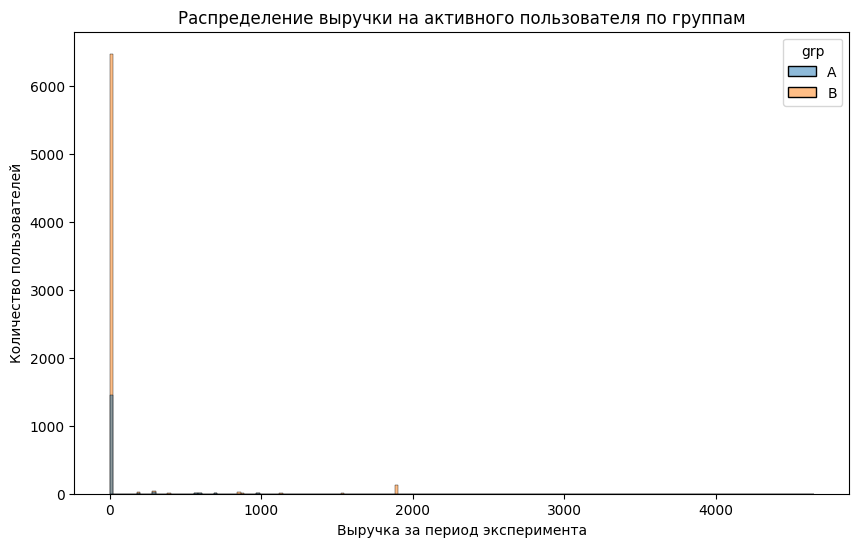

In [210]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

plt.figure(figsize=(10, 6))

sns.histplot(df, x='rev', hue='grp', stat='count')
plt.title('Распределение выручки на активного пользователя по группам')
plt.xlabel('Выручка за период эксперимента')
plt.ylabel('Количество пользователей')
plt.show()


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Распределения выручки на пользователя в обеих группах <b>асимметричные</b>, с правым хвостом. Большинство значений равны нулю: эти пользователи не совершили оплату. Среди положительных значений в B заметен пик около 1900.</p>
    <p style="font-size: 14px;">Посмотрим медиану, квартили и отдельные значения выручки.</p>
</div>

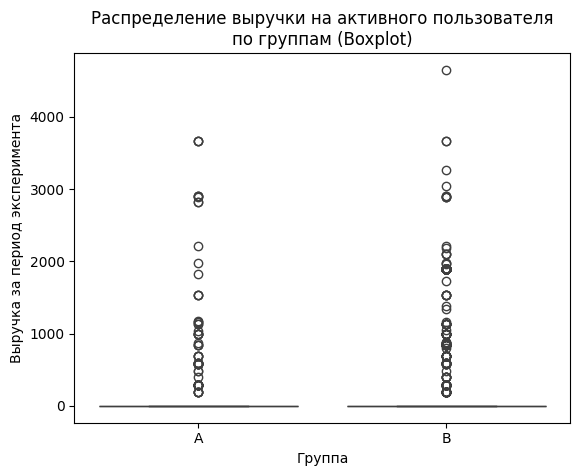

In [211]:
sns.boxplot(x='grp', y='rev', data=df)
plt.title('Распределение выручки на активного пользователя\nпо группам (Boxplot)')
plt.xlabel('Группа')
plt.ylabel('Выручка за период эксперимента')
plt.show()


In [212]:
df.groupby('grp')['rev'].describe()

,count,mean,std,min,25%,50%,75%,max
grp,,,,,,,,
A,1535.0,47.439739,290.766992,0.0,0.0,0.0,0.0,3660.0
B,6793.0,57.864567,313.197487,0.0,0.0,0.0,0.0,4650.0


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">В обеих группах медиана, первый и третий квартили равны нулю, поэтому «коробка» на графике сжимается в линию.</p>
    <p style="font-size: 14px;">Межквартильный размах также равен нулю, поэтому boxplot отмечает все положительные оплаты как выбросы. Это особенность распределения, а не признак ошибочных данных. Максимальная выручка на пользователя составляет 3660 в A и 4650 в B.</p>
</div>

Для сравнения ARPU используем выручку каждого пользователя, включая нули. Предполагаем, что наблюдения независимы, а распределение пользователей по группам проведено корректно.

Для сравнения средних используем **t-test Тест Уэлча.** Он не требует равенства дисперсий. Также ненормальность распределения исходной выручки сама по себе не исключает сравнение средних t-тестом при больших выборках. Сам тест будет проведен ниже.

Графики выше уже показывают, что распределения выручки отличаются от нормального. 

**В качестве учебной тренировки:
1) Проверим данные на нормальность (тест Шапиро–Уилка, Q-Q плот).
2) Проверим равенство дисперсий (стандартный тест Стьюдента требует равенства дисперсий).**

**H₀:** выручка на пользователя имеет нормальное распределение.

**H₁:** распределение выручки на пользователя не является нормальным.

В группе B больше 5000 наблюдений, поэтому p-value теста Шапиро–Уилка может быть неточным. Учитываем это ограничение при интерпретации результата.


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;"><b>Тест Шапиро–Уилка на нормальность данных</b></p>
    <p style="font-size: 14px;">Гипотезы проверяем отдельно для каждой группы:</p>
    <p style="font-size: 14px;"><b>H₀</b>: выручка на пользователя в рассматриваемой группе имеет нормальное распределение.</p>
    <p style="font-size: 14px;"><b>H₁</b>: распределение выручки на пользователя в рассматриваемой группе отличается от нормального.</p>
</div>

In [213]:
from scipy.stats import shapiro

rev_A = df.loc[df['grp'] == 'A', 'rev']
rev_B = df.loc[df['grp'] == 'B', 'rev']

stat_A, p_A = shapiro(rev_A)
stat_B, p_B = shapiro(rev_B)

print(f'A: p-value = {p_A:.4g}')
print(f'B: p-value = {p_B:.4g}')


A: p-value = 1.24e-63
B: p-value = 2.449e-99


/Users/nvknkhv/VSCodeProjects/e_commerce_data_analysis/.venv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 6793.
  res = hypotest_fun_out(*samples, **kwds)


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">В обеих группах получены p-value < 0.05. Отвергаем гипотезу о нормальности выручки на пользователя для обеих групп.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Есть еще один визуальный способ оценки нормальности распределения - <b>Q–Q plot</b>: если распределение близко к нормальному, наблюдаемые квантили должны располагаться примерно вдоль теоретической прямой. Существенные систематические отклонения от прямой будут свидетельствовать о нарушении предположения о нормальности.</p>
    <p style="font-size: 14px;">Ради интереса построим такой график.</p>
</div>

Text(0.5, 1.0, 'Q-Q plot: Проверка нормальности распределения Revenue в Группе А')

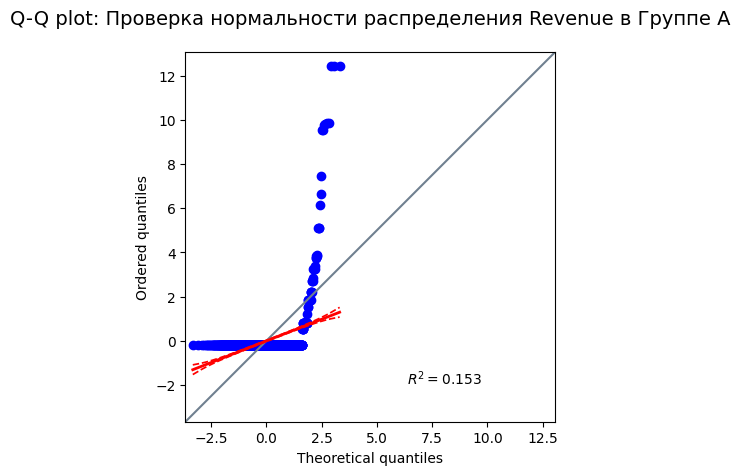

In [214]:
import pingouin as pg

pg.qqplot(rev_A)
plt.title('Q-Q plot: Проверка нормальности распределения Revenue в Группе А', 
          fontsize=14, pad=20)

Text(0.5, 1.0, 'Q-Q plot: Проверка нормальности распределения Revenue в Группе B')

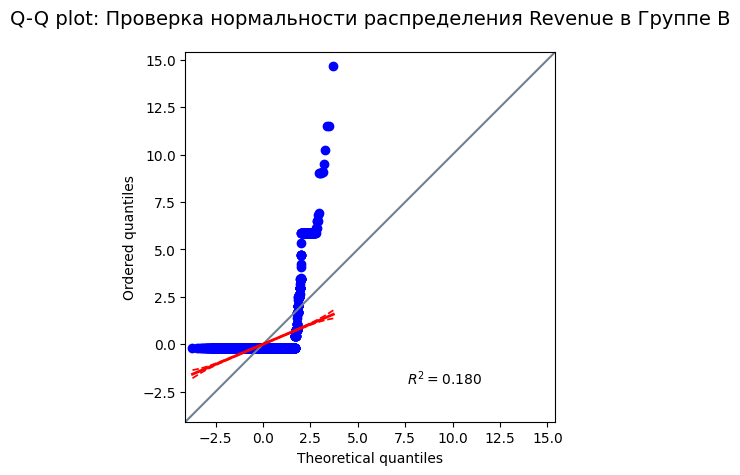

In [215]:
pg.qqplot(rev_B)
plt.title('Q-Q plot: Проверка нормальности распределения Revenue в Группе B', 
          fontsize=14, pad=20)

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Проверим равенство дисперсий в тестовой и контрольной группах.</p>
    <p style="font-size: 14px;">Поскольку распределения rev в обеих группах отличаются от нормального, для проверки равенства дисперсий применим устойчивый к ненормальности <b>критерий Левена</b>.</p>
     <p style="font-size: 14px;"><b>Гипотезы:</b></p>
    <p style="font-size: 14px;"><b>H₀</b>: дисперсии A и B равны.</p>
    <p style="font-size: 14px;"><b>H₁</b>: дисперсии A и B различаются.</p>
</div>

In [216]:
from scipy.stats import levene
stat, p_value = levene(rev_A, rev_B)
print(f"Статистика: {stat}, p-value: {p_value:.4f}")

Статистика: 1.4233907944574797, p-value: 0.2329


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">p-value = 0.2329 > 0.05: статистически значимых различий дисперсий не обнаружено, не отвергаем гипотезу о равенстве дисперсий.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Для сравнения средней выручки на пользователя применим <b>двухвыборочный t-тест Уэлча</b>, не предполагающий равенство дисперсий. При независимых наблюдениях и конечной дисперсии ЦПТ обосновывает приближение распределения выборочного среднего к нормальному с ростом выборки. Здесь используем это приближение с учётом описанной выше асимметрии выручки.</p>
    <p style="font-size: 14px;">Гипотезы:</p>
    <p style="font-size: 14px;"><b>H₀</b>: средняя выручка на пользователя одинакова в группах A и B.</p>
    <p style="font-size: 14px;"><b>H₁</b>: средняя выручка на пользователя различается между группами.</p>
</div>

In [217]:
import scipy.stats as st

arpu_diff = rev_B.mean() - rev_A.mean()

arpu_test = st.ttest_ind(rev_B, rev_A, equal_var=False)
arpu_ci = arpu_test.confidence_interval(confidence_level=0.95)

print(f'Разница ARPU (B − A): {arpu_diff:.2f}')

print(f't-статистика (B − A): {arpu_test.statistic:.4f}')
print(f'p-value: {arpu_test.pvalue:.4f}')
print(f'95% доверительный интервал (B − A): [{arpu_ci.low:.2f}; {arpu_ci.high:.2f}]')


Разница ARPU (B − A): 10.42
t-статистика (B − A): 1.2503
p-value: 0.2113
95% доверительный интервал (B − A): [-5.93; 26.77]


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">По результатам двухвыборочного t-теста Уэлча получено <b>p-value = 0.2113</b>, что превышает уровень значимости 0.05. Следовательно, нулевая гипотеза не отвергается: <b>статистически значимых различий в ARPU не обнаружено</b>.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;"><b>ARPPU</b></p>
    <p style="font-size: 14px;">Рассмотрим среднюю выручку на платящего пользователя как диагностическую метрику. Она поможет объяснить различие ARPU между группами.</p>
    <p style="font-size: 14px;">Для расчёта используем только активных пользователей с известной группой, у которых rev > 0. Каждый пользователь представлен одной строкой.</p>
</div>

In [218]:
rev_paid = df.loc[df['rev'] > 0]
rev_paid_A = rev_A.loc[df['rev'] > 0]
rev_paid_B = rev_B.loc[df['rev'] > 0]

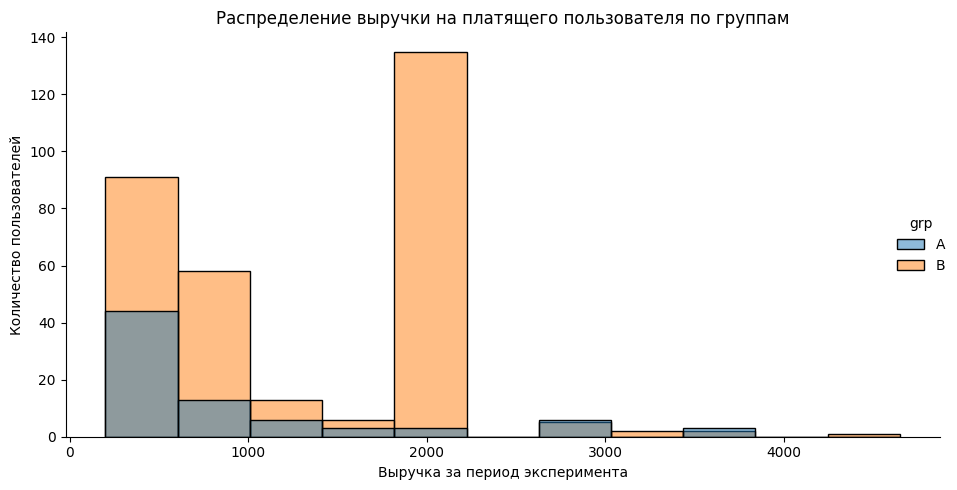

In [219]:
g = sns.displot(data=rev_paid, x="rev", hue="grp", height=5, aspect=1.8)
g.set_axis_labels('Выручка за период эксперимента', 'Количество пользователей')
g.ax.set_title('Распределение выручки на платящего пользователя по группам')
g.figure.tight_layout()
plt.show()


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
<p style="font-size: 14px;">Видим, что распределения отличаются от нормальных. Для группы B  - бимодальное, для обеих групп - скошено вправо.</p>
<p style="font-size: 14px;">Гипотезы:</p>
    <p style="font-size: 14px;"><b>H₀:</b> средняя выручка среди платящих пользователей одинакова в группах A и B.</p>
    <p style="font-size: 14px;"><b>H₁:</b> средняя выручка среди платящих пользователей различается группах A и B.</p>
    <p style="font-size: 14px;">Используем двусторонний t-тест Уэлча при α = 0,05. Он не требует равенства дисперсий. Дополнительно рассчитаем 95% доверительный интервал разницы B − A.</p>
    <p style="font-size: 14px;">В данной метрике не будем проверять нормальность и равенство дисперсий как выше, сразу приступим к тесту.</p>
</div>

In [220]:
from scipy.stats import ttest_ind

arppu_diff = rev_paid_B.mean() - rev_paid_A.mean()

arppu_test = ttest_ind(rev_paid_B, rev_paid_A, equal_var=False)
arppu_ci = arppu_test.confidence_interval(confidence_level=0.95)

print(f'ARPPU в группе A: {rev_paid_A.mean():.2f}')
print(f'ARPPU в группе B: {rev_paid_B.mean():.2f}')
print(f'Разница ARPPU (B − A): {arppu_diff:.2f}')

print(f't-статистика (B − A): {arppu_test.statistic:.4f}')
print(f'p-value: {arppu_test.pvalue:.4f}')
print(f'95% доверительный интервал (B − A): [{arppu_ci.low:.2f}; {arppu_ci.high:.2f}]')


ARPPU в группе A: 933.59
ARPPU в группе B: 1255.83
Разница ARPPU (B − A): 322.24
t-статистика (B − A): 2.8426
p-value: 0.0054
95% доверительный интервал (B − A): [97.52; 546.96]


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Тест Уэлча дал <b>p-value = 0,0054</b> при α = 0,05,  отвергаем H₀: <b>обнаружено статистически значимое различие ARPPU</b>. 95% доверительный интервал разницы B − A: <b>[97,52; 546,96] - не включает 0.</b>.</p>
</div>

<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">4. Вывод</b>
</div>

**1. Гипотеза о равенстве конверсии в оплату (CR)**

В группе A оплату совершили 5,08% активных пользователей, в группе B - 4,61%. Статистически значимого различия между группами не обнаружено. Тест не показал, что новая механика меняет долю платящих пользователей.

**2. Гипотеза о равенстве средней выручки на активного пользователя (ARPU)**

В группе A на одного активного пользователя пришлось 47,44, в группе B - 57,86.  Статистически значимого различия между группами не обнаружено. Тест не показал, что новая механика увеличивает выручку на активного пользователя.

**3. Гипотеза о равенстве средней выручки на платящего пользователя (ARPPU)**

В группе A средняя выручка на платящего пользователя составила 933,59, в группе B — 1255,83. ARPPU в группе B статистически значимо выше. Однако это не означает, что благодаря новой механике те же пользователи стали платить больше: различие может быть связано как с суммами покупок, так и с тем, какие пользователи совершили оплату. Поэтому ARPPU используем для объяснения результатов вместе с CR и ARPU; его роста недостаточно для решения о запуске.

**Общий вывод**

Пока **не рекомендую вводить новую механику оплаты для всех пользователей**: ARPPU в тестовой группе значимо выше, но рост выручки на активного пользователя ARPU и изменение конверсии в оплату статистически не подтверждены.

149 плательщиков не вошли в анализ, поскольку их нет в файле активности. Рекомендуется уточнить причину: если их активность просто не записалась, таких пользователей следует учесть и пересчитать результаты. Пока выводы относятся только к пользователям из файла активности, для которых известна группа АБ теста.

Дополнительно рекомендуется уточнить настройки системы сплитования и проверить валидность распределения пользователей: соответствует ли фактическое соотношение групп A и B (около 20/80) запланированному.